<a href="https://colab.research.google.com/github/Pappas313/SQLAlchemy/blob/main/Advanced_SQLAlchemy_%E2%80%94_Complete_E_Commerce_Backend.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Advanced SQLAlchemy — E-Commerce Order Management & Inventory Analytics**

For your next Google Colab project, I recommend building a Production-Style E-Commerce Order Management System using Python, SQLAlchemy 2.0, PostgreSQL, Alembic, Pandas, and Plotly.

Unlike your previous Financial Risk Analytics project, this one focuses on complex database relationships, inventory management, transactional consistency, order processing, and SQL performance optimization.


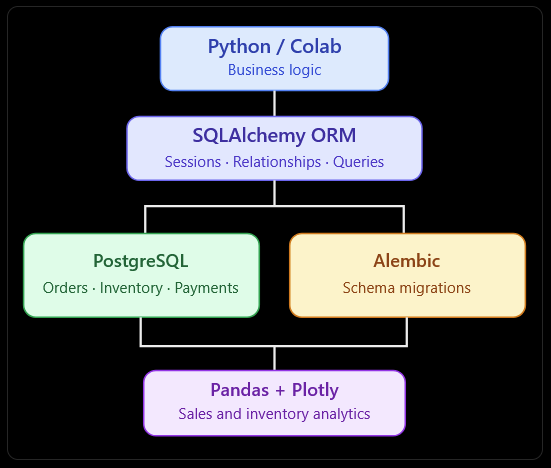

**1. Project requirements**

You'll implement:

Module	Features

Customer Management	Customers, addresses, purchase history

Product Catalog	Products, categories, pricing

Inventory	Stock quantities, reservations, stock movements

Order Management	Orders, order items, order statuses

Payments	Payment records, refunds, payment status

Analytics	Revenue, best-selling products, inventory trends

Database Migrations	Alembic revisions and schema changes

**2. Advanced SQLAlchemy concepts**

This project will teach you features that are particularly relevant to enterprise backend development:

•	One-to-many relationships: Customer → Orders.

•	Many-to-many relationships: Products ↔ Orders through OrderItems.

•	Transactional consistency: Create an order and reserve stock atomically.

•	Concurrency control: Prevent overselling using PostgreSQL row-level locks.

•	Optimistic concurrency: Detect conflicting inventory updates.
•	Eager loading: Avoid N+1 queries with selectinload() and joinedload().

•	SQL window functions: Rank best-selling products and calculate running revenue.

•	CTEs and subqueries: Build complex sales and inventory reports.

•	Alembic migrations: Evolve the schema safely over time.

**3. Database entity relationships**



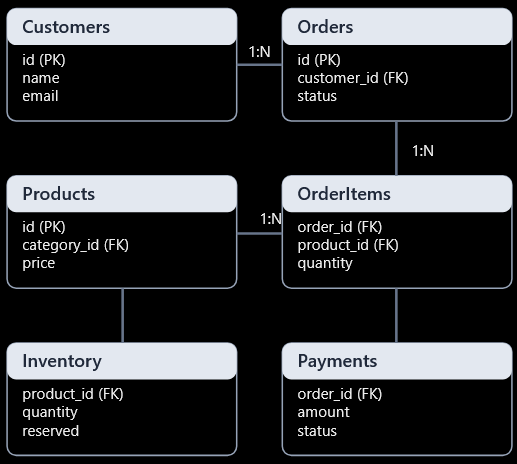

**4. Start in Google Colab**

**Step 1 — Install dependencies**

In [1]:

%pip -q install "sqlalchemy>=2.0,<3" "psycopg[binary]" alembic pandas numpy plotly faker


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 48.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.4/270.4 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 83.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.5/215.5 kB 19.2 MB/s eta 0:00:00


**Step 2 — Import libraries**

In [2]:

from datetime import datetime, timezone
from decimal import Decimal

from sqlalchemy import (
    create_engine, String, ForeignKey,
    Numeric, Integer, DateTime,
    select, func, CheckConstraint
)

from sqlalchemy.orm import (
    DeclarativeBase, Mapped,
    mapped_column, relationship,
    sessionmaker
)

from faker import Faker

fake = Faker()


**Step 3 — Configure the database**

For a quick standalone start, use SQLite. Later, we'll migrate to PostgreSQL for proper concurrent order processing.

In [3]:

engine = create_engine(
    "sqlite:///ecommerce.db",
    echo=False
)

class Base(DeclarativeBase):
    pass

SessionLocal = sessionmaker(
    bind=engine,
    expire_on_commit=False
)

print("Database configured")


Database configured


**Step 4 — Define customers and products**

In [4]:

class Customer(Base):
    __tablename__ = "customers"

    id: Mapped[int] = mapped_column(primary_key=True)
    name: Mapped[str] = mapped_column(String(120))
    email: Mapped[str] = mapped_column(
        String(180), unique=True
    )

    orders: Mapped[list["Order"]] = relationship(
        back_populates="customer"
    )


class Product(Base):
    __tablename__ = "products"

    id: Mapped[int] = mapped_column(primary_key=True)
    name: Mapped[str] = mapped_column(String(150))
    price: Mapped[Decimal] = mapped_column(
        Numeric(12, 2)
    )
    stock: Mapped[int] = mapped_column(
        Integer, default=0
    )

    __table_args__ = (
        CheckConstraint("price >= 0"),
        CheckConstraint("stock >= 0"),
    )


**Step 5 — Define orders and order items**

In [5]:

class Order(Base):
    __tablename__ = "orders"

    id: Mapped[int] = mapped_column(primary_key=True)
    customer_id: Mapped[int] = mapped_column(
        ForeignKey("customers.id")
    )
    status: Mapped[str] = mapped_column(
        String(30), default="pending"
    )
    created_at: Mapped[datetime] = mapped_column(
        DateTime, default=datetime.utcnow
    )

    customer: Mapped["Customer"] = relationship(
        back_populates="orders"
    )
    items: Mapped[list["OrderItem"]] = relationship(
        back_populates="order",
        cascade="all, delete-orphan"
    )


class OrderItem(Base):
    __tablename__ = "order_items"

    order_id: Mapped[int] = mapped_column(
        ForeignKey("orders.id"), primary_key=True
    )
    product_id: Mapped[int] = mapped_column(
        ForeignKey("products.id"), primary_key=True
    )
    quantity: Mapped[int] = mapped_column(Integer)
    unit_price: Mapped[Decimal] = mapped_column(
        Numeric(12, 2)
    )

    order: Mapped["Order"] = relationship(
        back_populates="items"
    )
    product: Mapped["Product"] = relationship()

    __table_args__ = (
        CheckConstraint("quantity > 0"),
    )


Base.metadata.create_all(engine)

print("E-commerce database tables created")


E-commerce database tables created


**Step 6 — Insert sample customers and products**

In [6]:

with SessionLocal.begin() as session:
    customers = [
        Customer(
            name=fake.name(),
            email=f"customer{i}@example.com"
        )
        for i in range(1, 101)
    ]

    products = [
        Product(
            name=f"Product {i}",
            price=Decimal(str(
                round(fake.pyfloat(
                    min_value=10,
                    max_value=500,
                    right_digits=2
                ), 2)
            )),
            stock=100
        )
        for i in range(1, 51)
    ]

    session.add_all(customers + products)

print("100 customers and 50 products inserted")


100 customers and 50 products inserted


**Step 7 — Create an order and update inventory**

In [7]:

def create_order(customer_id, product_id, quantity):
    if quantity <= 0:
        raise ValueError("Quantity must be positive")

    with SessionLocal.begin() as session:
        product = session.get(Product, product_id)

        if product is None:
            raise ValueError("Product not found")

        if product.stock < quantity:
            raise ValueError("Insufficient stock")

        order = Order(
            customer_id=customer_id,
            status="confirmed"
        )

        order.items.append(
            OrderItem(
                product_id=product.id,
                quantity=quantity,
                unit_price=product.price
            )
        )

        product.stock -= quantity
        session.add(order)
        session.flush()

        order_id = order.id

    return order_id


order_id = create_order(
    customer_id=1,
    product_id=1,
    quantity=2
)

print("Order created:", order_id)


Order created: 1


**Important:** This is an atomic transaction, but SQLite does not provide PostgreSQL-style row-level locking. For production-safe inventory updates with concurrent buyers, we'll implement SELECT ... FOR UPDATE or conditional atomic updates in PostgreSQL.

**Step 8 — Query orders with JOINs**

In [8]:

stmt = (
    select(
        Order.id.label("order_id"),
        Customer.name.label("customer"),
        Product.name.label("product"),
        OrderItem.quantity,
        OrderItem.unit_price,
        (
            OrderItem.quantity * OrderItem.unit_price
        ).label("line_total")
    )
    .join(Customer, Order.customer_id == Customer.id)
    .join(OrderItem, Order.id == OrderItem.order_id)
    .join(Product, OrderItem.product_id == Product.id)
)

with SessionLocal() as session:
    rows = session.execute(stmt).mappings().all()

import pandas as pd
display(pd.DataFrame(rows))


,customer,line_total,order_id,product,quantity,unit_price
0,Nicole Hull,191.94,1,Product 1,2,95.97


**Advanced SQLAlchemy  — Complete E-Commerce Backend**

We'll continue your E-Commerce Order Management & Inventory Analytics project and implement all seven modules in Google Colab, using PostgreSQL, SQLAlchemy 2.0, Alembic, Pandas, Plotly, and Pytest.

This version goes beyond basic CRUD operations. It introduces concurrency-safe checkout, normalized inventory and payments, 100,000 synthetic orders, database analytics, dashboards, and integration testing.

**Architecture**

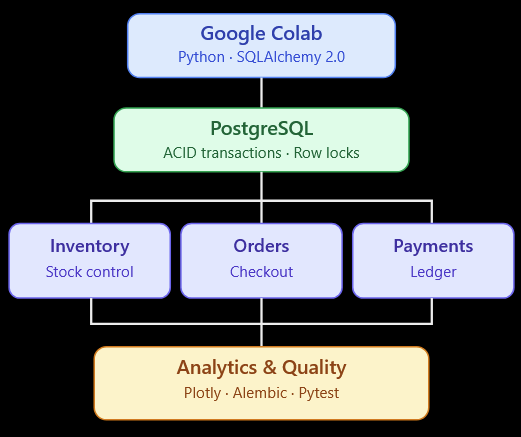

Implementation plan

Phase	Deliverable

1	PostgreSQL environment and project structure

2	Normalized inventory, orders, and payment models

3	Alembic initial migration

4	Concurrency-safe checkout service

5	Generate 100,000 synthetic orders

6	Advanced SQL revenue and inventory analytics

7	Interactive Plotly dashboards

8	Pytest integration and concurrency tests

We'll use a new PostgreSQL database for this project so it doesn't interfere with your previous Financial Risk Analytics database.

**Phase 1 — Set up PostgreSQL in Google Colab**

**Step 1. Install dependencies**



In [9]:

!apt-get update -qq
!apt-get install -y -qq postgresql postgresql-contrib > /dev/null

%pip -q install "sqlalchemy>=2.0,<3" "psycopg[binary]" alembic faker pandas numpy plotly pytest


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


**Notes:** PostgreSQL runs locally inside the Colab virtual machine. All database data will be lost if Colab resets the runtime, unless you export or back up the database.

**Step 2. Start PostgreSQL and create the database**

In [10]:

import os
import secrets
import subprocess
from pathlib import Path

subprocess.run(
    ["service", "postgresql", "start"],
    check=True
)

DB_NAME = "ecommerce_analytics"
DB_USER = "ecommerce_app"
DB_PASSWORD = secrets.token_urlsafe(24)

def postgres_admin(sql):
    return subprocess.run(
        [
            "runuser", "-u", "postgres",
            "--", "psql",
            "-v", "ON_ERROR_STOP=1",
            "-c", sql
        ],
        capture_output=True,
        text=True,
        check=True
    )

postgres_admin(
    f"CREATE ROLE {DB_USER} LOGIN PASSWORD '{DB_PASSWORD}'"
)

postgres_admin(
    f"CREATE DATABASE {DB_NAME} OWNER {DB_USER}"
)

print("Database created:", DB_NAME)


Database created: ecommerce_analytics


Run this cell once per fresh Colab runtime. Re-running the CREATE ROLE or CREATE DATABASE commands will raise an error if they already exist.

**Step 3. Configure the project**

In [11]:

from sqlalchemy.engine import URL

PROJECT = Path("/content/ecommerce_platform")
PROJECT.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT)

url = URL.create(
    "postgresql+psycopg",
    username=DB_USER,
    password=DB_PASSWORD,
    host="127.0.0.1",
    port=5432,
    database=DB_NAME
)

os.environ["DATABASE_URL"] = url.render_as_string(
    hide_password=False
)

print("Project directory:", PROJECT)


Project directory: /content/ecommerce_platform


**Step 4. Create the database connection module**

In [12]:

%%writefile database.py
import os
from sqlalchemy import create_engine
from sqlalchemy.orm import sessionmaker

engine = create_engine(
    os.environ["DATABASE_URL"],
    pool_pre_ping=True,
    pool_size=5,
    max_overflow=10
)

SessionLocal = sessionmaker(
    bind=engine,
    expire_on_commit=False
)


Writing database.py


**Phase 2 — Normalized database models**

Our normalized design separates product information from stock, stock movements, orders, payments, and refunds.

A product can have stock at multiple warehouses. An order can contain multiple items and have multiple payment attempts.

**Step 5. Create all SQLAlchemy models**

In [13]:

%%writefile models.py
from datetime import datetime
from decimal import Decimal

from sqlalchemy import (
    String, ForeignKey, Numeric, Integer,
    DateTime, CheckConstraint, UniqueConstraint,
    Index, func
)
from sqlalchemy.orm import (
    DeclarativeBase, Mapped,
    mapped_column, relationship
)


class Base(DeclarativeBase):
    pass


class Customer(Base):
    __tablename__ = "customers"

    id: Mapped[int] = mapped_column(primary_key=True)
    name: Mapped[str] = mapped_column(String(120))
    email: Mapped[str] = mapped_column(
        String(180), unique=True
    )


class Category(Base):
    __tablename__ = "categories"

    id: Mapped[int] = mapped_column(primary_key=True)
    name: Mapped[str] = mapped_column(
        String(100), unique=True
    )


class Product(Base):
    __tablename__ = "products"

    id: Mapped[int] = mapped_column(primary_key=True)
    category_id: Mapped[int] = mapped_column(
        ForeignKey("categories.id")
    )
    sku: Mapped[str] = mapped_column(
        String(50), unique=True
    )
    name: Mapped[str] = mapped_column(String(150))
    price: Mapped[Decimal] = mapped_column(
        Numeric(12, 2)
    )

    __table_args__ = (
        CheckConstraint("price >= 0"),
    )


class Warehouse(Base):
    __tablename__ = "warehouses"

    id: Mapped[int] = mapped_column(primary_key=True)
    name: Mapped[str] = mapped_column(String(100))


class Inventory(Base):
    __tablename__ = "inventory"

    id: Mapped[int] = mapped_column(primary_key=True)
    product_id: Mapped[int] = mapped_column(
        ForeignKey("products.id")
    )
    warehouse_id: Mapped[int] = mapped_column(
        ForeignKey("warehouses.id")
    )
    quantity: Mapped[int] = mapped_column(
        Integer, default=0
    )
    reserved: Mapped[int] = mapped_column(
        Integer, default=0
    )

    __table_args__ = (
        UniqueConstraint(
            "product_id", "warehouse_id"
        ),
        CheckConstraint("quantity >= 0"),
        CheckConstraint("reserved >= 0"),
        CheckConstraint("reserved <= quantity"),
    )


class Order(Base):
    __tablename__ = "orders"

    id: Mapped[int] = mapped_column(primary_key=True)
    customer_id: Mapped[int] = mapped_column(
        ForeignKey("customers.id")
    )
    status: Mapped[str] = mapped_column(
        String(30), default="pending"
    )
    total_amount: Mapped[Decimal] = mapped_column(
        Numeric(14, 2)
    )
    created_at: Mapped[datetime] = mapped_column(
        DateTime(timezone=True),
        server_default=func.now()
    )

    items: Mapped[list["OrderItem"]] = relationship(
        back_populates="order",
        cascade="all, delete-orphan"
    )


class OrderItem(Base):
    __tablename__ = "order_items"

    id: Mapped[int] = mapped_column(primary_key=True)
    order_id: Mapped[int] = mapped_column(
        ForeignKey("orders.id")
    )
    product_id: Mapped[int] = mapped_column(
        ForeignKey("products.id")
    )
    quantity: Mapped[int] = mapped_column(Integer)
    unit_price: Mapped[Decimal] = mapped_column(
        Numeric(12, 2)
    )

    order: Mapped["Order"] = relationship(
        back_populates="items"
    )

    __table_args__ = (
        CheckConstraint("quantity > 0"),
    )


class StockMovement(Base):
    __tablename__ = "stock_movements"

    id: Mapped[int] = mapped_column(primary_key=True)
    inventory_id: Mapped[int] = mapped_column(
        ForeignKey("inventory.id")
    )
    order_id: Mapped[int | None] = mapped_column(
        ForeignKey("orders.id"), nullable=True
    )
    quantity_change: Mapped[int] = mapped_column(Integer)
    movement_type: Mapped[str] = mapped_column(String(30))
    created_at: Mapped[datetime] = mapped_column(
        DateTime(timezone=True),
        server_default=func.now()
    )


class Payment(Base):
    __tablename__ = "payments"

    id: Mapped[int] = mapped_column(primary_key=True)
    order_id: Mapped[int] = mapped_column(
        ForeignKey("orders.id")
    )
    amount: Mapped[Decimal] = mapped_column(
        Numeric(14, 2)
    )
    status: Mapped[str] = mapped_column(String(30))
    provider_reference: Mapped[str] = mapped_column(
        String(120), unique=True
    )
    created_at: Mapped[datetime] = mapped_column(
        DateTime(timezone=True),
        server_default=func.now()
    )


class Refund(Base):
    __tablename__ = "refunds"

    id: Mapped[int] = mapped_column(primary_key=True)
    payment_id: Mapped[int] = mapped_column(
        ForeignKey("payments.id")
    )
    amount: Mapped[Decimal] = mapped_column(
        Numeric(14, 2)
    )
    status: Mapped[str] = mapped_column(String(30))

    __table_args__ = (
        CheckConstraint("amount > 0"),
    )


Index(
    "ix_orders_customer_created",
    Order.customer_id,
    Order.created_at
)

Index(
    "ix_payments_order_status",
    Payment.order_id,
    Payment.status
)


Writing models.py


**Database design notes**

**Table	Responsibility**

customers	Customer identity

categories	Product classification

products	Product catalog and prices

warehouses	Physical storage locations

inventory	Available and reserved stock

orders	Order headers and totals

order_items	Products purchased in each order

stock_movements	Inventory audit history

payments	Payment attempts and results

refunds	Refund records

The total_amount field on orders is intentionally denormalized for efficient reporting. Application logic must keep it consistent with order item totals.
The model uses a simplified inventory representation: quantity is physical stock and reserved is the portion allocated to pending orders. Available stock is quantity - reserved.

**Phase 3 — Alembic database migrations**

**Step 6. Initialize Alembic**



In [14]:

import subprocess

subprocess.run(
    ["alembic", "init", "alembic"],
    check=True
)


CompletedProcess(args=['alembic', 'init', 'alembic'], returncode=0)

**Step 7. Configure Alembic**

In [15]:

%%writefile alembic/env.py
import os
from logging.config import fileConfig

from sqlalchemy import engine_from_config, pool
from alembic import context
from models import Base

config = context.config

if config.config_file_name:
    fileConfig(config.config_file_name)

target_metadata = Base.metadata


def run_migrations_offline():
    context.configure(
        url=os.environ["DATABASE_URL"],
        target_metadata=target_metadata,
        literal_binds=True,
        compare_type=True
    )

    with context.begin_transaction():
        context.run_migrations()


def run_migrations_online():
    settings = config.get_section(
        config.config_ini_section, {}
    ).copy()

    settings["sqlalchemy.url"] = (
        os.environ["DATABASE_URL"]
    )

    connectable = engine_from_config(
        settings,
        prefix="sqlalchemy.",
        poolclass=pool.NullPool
    )

    with connectable.connect() as connection:
        context.configure(
            connection=connection,
            target_metadata=target_metadata,
            compare_type=True
        )

        with context.begin_transaction():
            context.run_migrations()


if context.is_offline_mode():
    run_migrations_offline()
else:
    run_migrations_online()


Overwriting alembic/env.py


**Step 8. Generate and apply the migration**

In [16]:

subprocess.run(
    [
        "alembic", "revision",
        "--autogenerate",
        "-m", "initial_ecommerce_schema"
    ],
    check=True
)

subprocess.run(
    ["alembic", "upgrade", "head"],
    check=True
)


CompletedProcess(args=['alembic', 'upgrade', 'head'], returncode=0)

**Step 9. Verify the database**

In [17]:

from sqlalchemy import inspect
from database import engine

inspector = inspect(engine)

for table in inspector.get_table_names():
    print(table)


alembic_version
customers
orders
categories
products
inventory
warehouses
order_items
payments
refunds
stock_movements


**You should see ten business tables plus alembic_version.**

**Important:** We use Alembic rather than Base.metadata.create_all() so every schema change is version-controlled.

**Phase 4 — PostgreSQL concurrency-safe checkout**

This is one of the most important parts of the project.

Imagine two customers attempting to buy the last available product at the same time. Without concurrency control, both transactions might read the same stock quantity and oversell it.

PostgreSQL provides row-level locks using SELECT ... FOR UPDATE.

**Step 10. Seed the product catalog**

In [18]:

from decimal import Decimal
from models import (
    Customer, Category, Product,
    Warehouse, Inventory
)
from database import SessionLocal

with SessionLocal.begin() as session:
    category = Category(name="Electronics")
    warehouse = Warehouse(name="Athens Warehouse")
    customer = Customer(
        name="Test Customer",
        email="test@example.com"
    )

    session.add_all([category, warehouse, customer])
    session.flush()

    product = Product(
        category_id=category.id,
        sku="LAPTOP-001",
        name="Professional Laptop",
        price=Decimal("1299.00")
    )
    session.add(product)
    session.flush()

    stock = Inventory(
        product_id=product.id,
        warehouse_id=warehouse.id,
        quantity=10,
        reserved=0
    )
    session.add(stock)

print("Sample catalog created")


Sample catalog created


**Step 11. Implement checkout with row-level locking**

In [19]:

%%writefile checkout.py
from decimal import Decimal
from uuid import uuid4

from sqlalchemy import select
from database import SessionLocal
from models import (
    Customer, Product, Inventory,
    Order, OrderItem, Payment, StockMovement
)


def checkout(customer_id, product_id, quantity):
    if quantity <= 0:
        raise ValueError("Quantity must be positive")

    with SessionLocal.begin() as session:
        customer = session.get(Customer, customer_id)
        if customer is None:
            raise ValueError("Customer not found")

        product = session.get(Product, product_id)
        if product is None:
            raise ValueError("Product not found")

        # Lock the inventory row until commit/rollback
        inventory = session.scalar(
            select(Inventory)
            .where(Inventory.product_id == product_id)
            .order_by(Inventory.id)
            .with_for_update()
        )

        if inventory is None:
            raise ValueError("Inventory not found")

        available = (
            inventory.quantity - inventory.reserved
        )

        if available < quantity:
            raise ValueError("Insufficient stock")

        total = product.price * Decimal(quantity)

        order = Order(
            customer_id=customer_id,
            status="pending_payment",
            total_amount=total
        )
        session.add(order)
        session.flush()

        session.add(OrderItem(
            order_id=order.id,
            product_id=product_id,
            quantity=quantity,
            unit_price=product.price
        ))

        # Reserve stock; physical stock is unchanged
        inventory.reserved += quantity

        session.add(StockMovement(
            inventory_id=inventory.id,
            order_id=order.id,
            quantity_change=0,
            movement_type="reservation"
        ))

        # Simulated payment attempt, not a real charge
        session.add(Payment(
            order_id=order.id,
            amount=total,
            status="pending",
            provider_reference=str(uuid4())
        ))

        return order.id


Writing checkout.py


**How it works:** PostgreSQL locks the selected inventory row. A second checkout for the same product waits until the first transaction commits or rolls back, then checks the updated available stock.

The order and payment are initially pending. No real payment provider is contacted.

For a multi-product checkout, lock inventory rows in a consistent order to reduce deadlock risk. A production implementation should also support idempotency keys, reservation expiry, retries, and payment webhooks.

**Step 12. Execute checkout**

In [20]:

from checkout import checkout
from sqlalchemy import select
from models import Inventory
from database import SessionLocal

order_id = checkout(
    customer_id=1,
    product_id=1,
    quantity=2
)

with SessionLocal() as session:
    stock = session.scalar(
        select(Inventory).where(
            Inventory.product_id == 1
        )
    )

    print("Order:", order_id)
    print("Physical stock:", stock.quantity)
    print("Reserved stock:", stock.reserved)
    print("Available:", stock.quantity - stock.reserved)


Order: 1
Physical stock: 10
Reserved stock: 2
Available: 8


**Step 13. Confirm a simulated payment and fulfill the order**

In [21]:

%%writefile fulfillment.py
from sqlalchemy import select
from database import SessionLocal
from models import (
    Order, OrderItem, Inventory,
    Payment, StockMovement
)


def fulfill_paid_order(order_id):
    with SessionLocal.begin() as session:
        order = session.scalar(
            select(Order)
            .where(Order.id == order_id)
            .with_for_update()
        )

        if order is None:
            raise ValueError("Order not found")

        if order.status == "fulfilled":
            return order_id

        if order.status != "pending_payment":
            raise ValueError("Invalid order status")

        payment = session.scalar(
            select(Payment)
            .where(Payment.order_id == order_id)
            .with_for_update()
        )

        if payment is None:
            raise ValueError("Payment not found")

        # Simulated payment success for this tutorial
        payment.status = "succeeded"

        items = session.scalars(
            select(OrderItem)
            .where(OrderItem.order_id == order_id)
            .order_by(OrderItem.product_id)
        ).all()

        for item in items:
            inventory = session.scalar(
                select(Inventory)
                .where(
                    Inventory.product_id == item.product_id
                )
                .order_by(Inventory.id)
                .with_for_update()
            )

            if inventory is None:
                raise ValueError("Inventory missing")

            if inventory.reserved < item.quantity:
                raise ValueError("Invalid reservation")

            inventory.reserved -= item.quantity
            inventory.quantity -= item.quantity

            session.add(StockMovement(
                inventory_id=inventory.id,
                order_id=order_id,
                quantity_change=-item.quantity,
                movement_type="sale"
            ))

        order.status = "fulfilled"

    return order_id


Writing fulfillment.py


In [22]:

from fulfillment import fulfill_paid_order

fulfill_paid_order(order_id)

with SessionLocal() as session:
    stock = session.get(Inventory, 1)

    print("Physical stock:", stock.quantity)
    print("Reserved:", stock.reserved)


Physical stock: 8
Reserved: 0


In a real application, fulfillment should occur only after verified payment confirmation from a trusted provider. This tutorial simulates that confirmation inside the database transaction.

**Phase 5 — Generate 100,000 synthetic orders**

We will use SQLAlchemy Core bulk inserts for performance instead of adding 100,000 ORM objects individually.

The generated orders are historical, fulfilled orders for analytics. They are inserted as a separate synthetic dataset and do not modify live inventory balances.

**Step 14. Generate bulk historical orders**

In [23]:

import random
from datetime import datetime, timedelta, timezone
from decimal import Decimal

from sqlalchemy import insert, select
from database import engine
from models import (
    Customer, Product, Order,
    OrderItem, Payment
)

random.seed(42)

# Add additional catalog records
with SessionLocal.begin() as session:
    session.add_all([
        Product(
            category_id=1,
            sku=f"ITEM-{i:04d}",
            name=f"Product {i}",
            price=Decimal(str(random.randint(10, 500)))
        )
        for i in range(2, 101)
    ])

    session.add_all([
        Customer(
            name=f"Customer {i}",
            email=f"customer{i}@example.com"
        )
        for i in range(2, 1001)
    ])

with engine.connect() as conn:
    customer_ids = conn.execute(
        select(Customer.id)
    ).scalars().all()

    product_data = conn.execute(
        select(Product.id, Product.price)
    ).all()

product_prices = {
    product_id: price
    for product_id, price in product_data
}

product_ids = list(product_prices)

TOTAL_ORDERS = 100_000
BATCH_SIZE = 2_000
base_date = datetime.now(timezone.utc)

for start in range(0, TOTAL_ORDERS, BATCH_SIZE):
    size = min(BATCH_SIZE, TOTAL_ORDERS - start)

    order_rows = []
    product_choices = []
    quantities = []

    for i in range(size):
        product_id = random.choice(product_ids)
        quantity = random.randint(1, 5)

        product_choices.append(product_id)
        quantities.append(quantity)

        order_rows.append({
            "customer_id": random.choice(customer_ids),
            "status": "fulfilled",
            "total_amount": (
                product_prices[product_id] * quantity
            ),
            "created_at": base_date - timedelta(
                days=random.randint(0, 364),
                hours=random.randint(0, 23)
            )
        })

    with engine.begin() as conn:
        ids = conn.execute(
            insert(Order).returning(Order.id),
            order_rows
        ).scalars().all()

        item_rows = [
            {
                "order_id": order_id,
                "product_id": product_id,
                "quantity": quantity,
                "unit_price": product_prices[product_id]
            }
            for order_id, product_id, quantity in zip(
                ids, product_choices, quantities
            )
        ]

        conn.execute(insert(OrderItem), item_rows)

        payment_rows = [
            {
                "order_id": order_id,
                "amount": item["unit_price"] * item["quantity"],
                "status": "succeeded",
                "provider_reference": f"SYN-{order_id}"
            }
            for order_id, item in zip(ids, item_rows)
        ]

        conn.execute(insert(Payment), payment_rows)

    if (start + size) % 20000 == 0:
        print(f"Inserted {start + size:,} orders")

print("Historical order generation completed")


Inserted 20,000 orders
Inserted 40,000 orders
Inserted 60,000 orders
Inserted 80,000 orders
Inserted 100,000 orders
Historical order generation completed


**Notes:** The bulk operation inserts order headers, items, and payment records in batches of 2,000. Each batch is atomic. If one batch fails, earlier committed batches remain.

Run this cell only once unless you intentionally want to add another 100,000 orders. These synthetic records are suitable for reporting demonstrations, not payment reconciliation or real inventory auditing.

**Step 15. Verify record counts**

In [24]:

from sqlalchemy import func, select

with SessionLocal() as session:
    for model in [Order, OrderItem, Payment]:
        count = session.scalar(
            select(func.count()).select_from(model)
        )
        print(model.__tablename__, f"{count:,}")


orders 100,001
order_items 100,001
payments 100,001


Expected counts after the earlier sample checkout and 100,000 generated orders:

**Table	Expected records**

Orders	100,001

Order items	100,001

Payments	100,001

**Phase 6 — Advanced SQL revenue analytics**

**Step 16. Monthly revenue with PostgreSQL date_trunc**



In [25]:

import pandas as pd
from sqlalchemy import select, func

month = func.date_trunc(
    "month", Order.created_at
).label("month")

stmt = (
    select(
        month,
        func.count(Order.id).label("orders"),
        func.sum(Order.total_amount).label("revenue"),
        func.avg(Order.total_amount).label("average_order")
    )
    .where(Order.status == "fulfilled")
    .group_by(month)
    .order_by(month)
)

with engine.connect() as conn:
    revenue_df = pd.read_sql(stmt, conn)

display(revenue_df)


,month,orders,revenue,average_order
0,2025-10-01 00:00:00+00:00,2542,1847892.0,726.944138
1,2025-11-01 00:00:00+00:00,8368,6024500.0,719.945029
2,2025-12-01 00:00:00+00:00,8403,6187490.0,736.342973
3,2026-01-01 00:00:00+00:00,8379,6090550.0,726.882683
4,2026-02-01 00:00:00+00:00,7783,5696452.0,731.909546
5,2026-03-01 00:00:00+00:00,8400,6127342.0,729.445476
6,2026-04-01 00:00:00+00:00,8116,6116062.0,753.580828
7,2026-05-01 00:00:00+00:00,8535,6287614.0,736.685882
8,2026-06-01 00:00:00+00:00,8250,6065293.0,735.187030
9,2026-07-01 00:00:00+00:00,8449,6257462.0,740.615694


This gives you monthly revenue, order count, and average order value.

**Step 17. Rank best-selling products**

In [26]:

from sqlalchemy import desc

stmt = (
    select(
        Product.name,
        func.sum(OrderItem.quantity).label("units_sold"),
        func.sum(
            OrderItem.quantity * OrderItem.unit_price
        ).label("revenue")
    )
    .join(OrderItem, Product.id == OrderItem.product_id)
    .join(Order, Order.id == OrderItem.order_id)
    .where(Order.status == "fulfilled")
    .group_by(Product.id, Product.name)
    .order_by(
        desc(func.sum(
            OrderItem.quantity * OrderItem.unit_price
        ))
    )
    .limit(10)
)

with engine.connect() as conn:
    top_products_df = pd.read_sql(stmt, conn)

display(top_products_df)


,name,units_sold,revenue
0,Professional Laptop,3159,4103541.0
1,Product 68,2989,1440698.0
2,Product 50,2877,1438500.0
3,Product 39,3074,1398670.0
4,Product 14,2981,1389146.0
5,Product 91,3031,1373043.0
6,Product 89,3052,1364244.0
7,Product 76,2943,1362609.0
8,Product 77,2996,1351196.0
9,Product 42,3190,1346180.0


**Step 18. Calculate cumulative revenue using a window function**

In [28]:

monthly = (
    select(
        func.date_trunc(
            "month", Order.created_at
        ).label("month"),
        func.sum(Order.total_amount).label("revenue")
    )
    .where(Order.status == "fulfilled")
    .group_by(
        func.date_trunc("month", Order.created_at)
    )
    .subquery()
)

# To prevent the GroupingError, we use the defined column expression directly in group_by
month_expr = func.date_trunc(
    "month", Order.created_at
).label("month")

monthly = (
    select(
        month_expr,
        func.sum(Order.total_amount).label("revenue")
    )
    .where(Order.status == "fulfilled")
    .group_by(month_expr)
    .subquery()
)

stmt = select(
    monthly.c.month,
    monthly.c.revenue,
    func.sum(monthly.c.revenue).over(
        order_by=monthly.c.month
    ).label("cumulative_revenue")
).order_by(monthly.c.month)

with engine.connect() as conn:
    cumulative_df = pd.read_sql(stmt, conn)

display(cumulative_df)


,month,revenue,cumulative_revenue
0,2025-10-01 00:00:00+00:00,1847892.0,1847892.0
1,2025-11-01 00:00:00+00:00,6024500.0,7872392.0
2,2025-12-01 00:00:00+00:00,6187490.0,14059882.0
3,2026-01-01 00:00:00+00:00,6090550.0,20150432.0
4,2026-02-01 00:00:00+00:00,5696452.0,25846884.0
5,2026-03-01 00:00:00+00:00,6127342.0,31974226.0
6,2026-04-01 00:00:00+00:00,6116062.0,38090288.0
7,2026-05-01 00:00:00+00:00,6287614.0,44377902.0
8,2026-06-01 00:00:00+00:00,6065293.0,50443195.0
9,2026-07-01 00:00:00+00:00,6257462.0,56700657.0


The SUM(...) OVER (ORDER BY ...) expression calculates a running total without collapsing the monthly rows.

**Step 19. Inventory availability report**

In [29]:

stmt = (
    select(
        Product.sku,
        Product.name,
        Warehouse.name.label("warehouse"),
        Inventory.quantity,
        Inventory.reserved,
        (
            Inventory.quantity - Inventory.reserved
        ).label("available")
    )
    .join(Product, Inventory.product_id == Product.id)
    .join(
        Warehouse,
        Inventory.warehouse_id == Warehouse.id
    )
    .order_by(
        (Inventory.quantity - Inventory.reserved).asc()
    )
)

with engine.connect() as conn:
    inventory_df = pd.read_sql(stmt, conn)

display(inventory_df)


,sku,name,warehouse,quantity,reserved,available
0,LAPTOP-001,Professional Laptop,Athens Warehouse,8,0,8


This query shows the live inventory records. The synthetic historical orders do not reduce these stock quantities.

**Phase 7 — Interactive Plotly dashboards**

**Step 20. Monthly revenue chart**

In [30]:

import plotly.express as px

revenue_df["revenue"] = revenue_df["revenue"].astype(float)

fig = px.bar(
    revenue_df,
    x="month",
    y="revenue",
    title="Monthly E-Commerce Revenue",
    labels={
        "month": "Month",
        "revenue": "Revenue (EUR)"
    },
    text_auto=".2s"
)

fig.update_layout(
    template="plotly_white",
    height=450
)

fig.show()


**Step 21. Best-selling products chart**

In [31]:

top_products_df["revenue"] = (
    top_products_df["revenue"].astype(float)
)

fig = px.bar(
    top_products_df,
    x="revenue",
    y="name",
    orientation="h",
    title="Top 10 Products by Revenue",
    labels={
        "revenue": "Revenue (EUR)",
        "name": "Product"
    }
)

fig.update_layout(
    template="plotly_white",
    yaxis={"categoryorder": "total ascending"}
)

fig.show()


**Step 22. Cumulative revenue chart**

In [32]:

cumulative_df["cumulative_revenue"] = (
    cumulative_df["cumulative_revenue"].astype(float)
)

fig = px.area(
    cumulative_df,
    x="month",
    y="cumulative_revenue",
    title="Cumulative E-Commerce Revenue",
    labels={
        "month": "Month",
        "cumulative_revenue": "Revenue (EUR)"
    }
)

fig.update_layout(template="plotly_white")
fig.show()


**Step 23. Inventory dashboard**

In [33]:

fig = px.bar(
    inventory_df,
    x="name",
    y=["available", "reserved"],
    barmode="stack",
    title="Available vs Reserved Inventory",
    labels={
        "name": "Product",
        "value": "Units",
        "variable": "Inventory Type"
    }
)

fig.update_layout(template="plotly_white")
fig.show()


These charts are interactive in Colab: you can hover over data points, zoom, pan, and export chart images using Plotly's built-in controls.

**Phase 8 — Pytest integration tests**

We'll write tests that use the real PostgreSQL database and verify SQLAlchemy's behavior.

**Step 24. Create checkout integration tests**

In [39]:
%%writefile /content/ecommerce_platform/test_checkout.py
from concurrent.futures import ThreadPoolExecutor
from decimal import Decimal
from uuid import uuid4

import pytest
from sqlalchemy import select

from database import SessionLocal
from models import (
    Customer, Product, Category,
    Warehouse, Inventory, Order
)
from checkout import checkout


@pytest.fixture
def test_data():
    suffix = uuid4().hex[:10]

    with SessionLocal.begin() as session:
        category = Category(name=f"Test-{suffix}")
        warehouse = Warehouse(name=f"Test-WH-{suffix}")
        customer = Customer(
            name="Integration Test",
            email=f"test-{suffix}@example.com"
        )

        session.add_all([category, warehouse, customer])
        session.flush()

        product = Product(
            category_id=category.id,
            sku=f"TEST-{suffix}",
            name="Test Product",
            price=Decimal("50.00")
        )
        session.add(product)
        session.flush()

        inventory = Inventory(
            product_id=product.id,
            warehouse_id=warehouse.id,
            quantity=10,
            reserved=0
        )
        session.add(inventory)
        session.flush()  # Generate the inventory.id before exiting the block

        result = (customer.id, product.id, inventory.id)

    yield result


def test_checkout_reserves_stock(test_data):
    customer_id, product_id, inventory_id = test_data

    order_id = checkout(customer_id, product_id, 3)

    with SessionLocal() as session:
        inventory = session.get(Inventory, inventory_id)
        order = session.get(Order, order_id)

        assert inventory.quantity == 10
        assert inventory.reserved == 3
        assert order.status == "pending_payment"
        assert order.total_amount == Decimal("150.00")


def test_checkout_rejects_insufficient_stock(test_data):
    customer_id, product_id, inventory_id = test_data

    with pytest.raises(ValueError, match="Insufficient stock"):
        checkout(customer_id, product_id, 11)

    with SessionLocal() as session:
        inventory = session.get(Inventory, inventory_id)
        assert inventory.reserved == 0


def test_checkout_rejects_invalid_quantity(test_data):
    customer_id, product_id, _ = test_data

    with pytest.raises(ValueError, match="Quantity must be positive"):
        checkout(customer_id, product_id, -1)


def test_concurrent_checkout_prevents_overselling(test_data):
    customer_id, product_id, inventory_id = test_data

    def attempt():
        try:
            return checkout(customer_id, product_id, 7)
        except ValueError as exc:
            return str(exc)

    with ThreadPoolExecutor(max_workers=2) as executor:
        results = list(executor.map(
            lambda _: attempt(), range(2)
        ))

    successes = [r for r in results if isinstance(r, int)]
    failures = [r for r in results if isinstance(r, str)]

    assert len(successes) == 1
    assert failures == ["Insufficient stock"]

    with SessionLocal() as session:
        inventory = session.get(Inventory, inventory_id)

        assert inventory.quantity == 10
        assert inventory.reserved == 7
        assert inventory.quantity - inventory.reserved == 3

Overwriting /content/ecommerce_platform/test_checkout.py


**Notes:** The concurrency test creates two threads that attempt to reserve seven units each from an initial stock of ten. Only one checkout should succeed.

The fixture generates unique products and customers, so tests do not depend on the earlier sample data. For a professional CI environment, use a dedicated test database and automatic cleanup rather than keeping the test records.

**Step 25. Run the tests**

In [40]:
import subprocess
import os

project_dir = "/content/ecommerce_platform"

result = subprocess.run(
    [
        "python", "-m", "pytest",
        os.path.join(project_dir, "test_checkout.py"),
        "-v", "-ra"
    ],
    cwd=project_dir,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr[-2000:])
assert result.returncode == 0, "Tests failed"

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/ecommerce_platform
plugins: Faker-40.43.0, anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.4, typeguard-4.6.0
collecting ... collected 4 items

test_checkout.py::test_checkout_reserves_stock PASSED                    [ 25%]
test_checkout.py::test_checkout_rejects_insufficient_stock PASSED        [ 50%]
test_checkout.py::test_checkout_rejects_invalid_quantity PASSED          [ 75%]
test_checkout.py::test_concurrent_checkout_prevents_overselling PASSED   [100%]

============================== 4 passed in 0.86s ===============================




The expected output is illustrative; actual test results will depend on execution in your Colab runtime.

**Step 26. Check the migration state**

In [41]:

for command in [
    ["alembic", "current"],
    ["alembic", "heads"],
    ["alembic", "check"]
]:
    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    print("$", " ".join(command))
    print(result.stdout)
    print(result.stderr[-500:])
    print("Exit code:", result.returncode)


$ alembic current
490650be18fb (head)

INFO  [alembic.runtime.migration] Context impl PostgresqlImpl.
INFO  [alembic.runtime.migration] Will assume transactional DDL.

Exit code: 0
$ alembic heads
490650be18fb (head)


Exit code: 0
$ alembic check
No new upgrade operations detected.

ger column 'stock_movements(id)', assuming SERIAL and omitting
INFO  [alembic.ddl.postgresql] Detected sequence named 'payments_id_seq' as owned by integer column 'payments(id)', assuming SERIAL and omitting
INFO  [alembic.ddl.postgresql] Detected sequence named 'customers_id_seq' as owned by integer column 'customers(id)', assuming SERIAL and omitting
INFO  [alembic.ddl.postgresql] Detected sequence named 'products_id_seq' as owned by integer column 'products(id)', assuming SERIAL and omitting

Exit code: 0


alembic check verifies whether autogeneration detects outstanding schema changes. An exit code of zero indicates that no new upgrade operations were detected.

**Phase 9 — Final project structure**

Your Google Colab project should now contain:

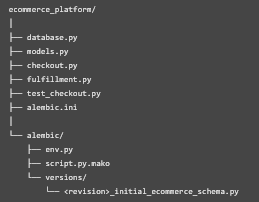

What you've implemented

**Capability	Technology**

Normalized database architecture	SQLAlchemy 2.0

PostgreSQL row-level locking	SELECT FOR UPDATE

Atomic checkout	SQLAlchemy sessions

Inventory reservations	PostgreSQL transactions

Payment and refund data models	SQLAlchemy ORM

Database migrations	Alembic

100,000 synthetic orders	SQLAlchemy Core bulk inserts

Revenue and inventory analytics	SQLAlchemy + PostgreSQL

Running totals and aggregation	SQL window functions

Interactive dashboards	Plotly

Integration and concurrency tests	Pytest

The current implementation is a working educational foundation, with a few important boundaries: payment confirmation is simulated, historical orders are not reconciled against inventory, refunds have a data model but no refund-processing service, and the tests need an isolated database for CI use.
